# Maxwell 3D BI-CIS pixel — IPA light trapping + DTI crosstalk suppression

The full back-illuminated (BI) CMOS image-sensor pixel of **Yokogawa et al., "IR sensitivity enhancement of CMOS Image Sensor with diffractive light trapping pixels", *Sci. Rep.* 7:3832 (2017)** — [doi.org/10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y) (open access).

This notebook puts the paper's textured Si surface inside a complete pixel: microlens → polymer spacer → textured Si photodiode.

**What you design here**

| | |
|---|---|
| **Model** | 3D time-harmonic Maxwell (full vector E field), Modified Born Series solver, λ = 850 nm |
| **Structure** | 1.2 μm pixel: spherical-cap microlens, polymer spacer, 3 μm Si photodiode whose top surface is the variable (samples A / B / C) |
| **Materials** | air, polymer (n = 1.60), SiO₂ (n = 1.45), absorbing crystalline Si (n = 3.653 + 0.00362i) |
| **Sources** | Part 1: x-polarized plane wave; Part 2: x-polarized Gaussian beam on the centre pixel only |

**The three samples** (the photodiode surface)
* **A** — flat Si surface (reference)
* **B** — 3×3 inverted-pyramid array (IPA), 400 nm pitch, SiO₂-filled
* **C** — IPA + deep trench isolation (DTI): SiO₂ trenches, 200 nm wide × 2 μm deep, on every pixel border

**Two experiments**
* **Part 1 — sensitivity:** one periodic pixel, uniform illumination → absorbed fraction in the photodiode and FOM = A_sample / A_flat.
  Expected: A = 11.7 %, B = 14.4 % (FOM 1.24), C = 15.0 % (FOM 1.29).
* **Part 2 — optical crosstalk:** an `N_PIX_XTALK × N_PIX_XTALK` pixel array (3×3 by default, 5×5 optional), only the centre pixel lit → absorbed power per photodiode.
  Expected neighbour-total / centre at 3×3: A 41.3 % (Gaussian tails baseline), B 100.1 %, C 46.2 %; at 5×5: A 45.0 %, B 130.3 %, C 53.7 %. Switched on/off with `RUN_CROSSTALK` (section 2.1).

These numbers describe this *simplified model* (perfect absorber below the photodiode, no AR layer, no color filters), not the physical device. The point of the example is the workflow: build the stack, run it, measure the absorption in each photodiode. Each simplification can be removed by extending the same medium-building code.

**Why a full-wave solver:** ray tracing cannot produce any of the Part 2 crosstalk, because the diffraction at the pyramids *is* the mechanism.

**Section 6 previews everything — model, materials, structure, sources, monitors and boundaries — before any simulation is run.**

Size: 7 solves, the largest 176.4 Mvoxel including boundaries, 13.14 GB of memory (service estimate).

### The paper's concept (Fig. 1)
(a) The pixel this notebook builds: microlens, inverted pyramids on the Si surface and DTI between pixels. The colour filters (OCCF) are left out; see the differences under Fig. 3. (b) The trapping mechanism: light refracted at the 54.7° facets is totally reflected at the pixel sidewall, i.e. the DTI, so it stays in its own pixel. Part 2 measures exactly this.

![Paper Fig. 1](img/paper_fig1.jpg)

*Figure reproduced from Yokogawa et al., Sci. Rep. 7:3832 (2017), [doi:10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y), under a [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) licence. Unmodified.*

### What this notebook reproduces (Fig. 3)
(a) Sample A, flat Si. (b) Sample B, with 400 nm pyramids (3 × 3 per pixel). (c) Sample C, with DTI 200 nm × 2 μm added. Pixel 1.2 μm, Si 3 μm, microlens 1.7 μm high with R = 0.85 μm: the same values used in section 2.3.

![Paper Fig. 3](img/paper_fig3.jpg)

*Figure reproduced from Yokogawa et al., Sci. Rep. 7:3832 (2017), [doi:10.1038/s41598-017-04200-y](https://doi.org/10.1038/s41598-017-04200-y), under a [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) licence. Unmodified.*

**Differences from the paper's pixel:**
* no colour filters: the polymer spacer takes their place (this is an 850 nm NIR study);
* no AR layer;
* no metal grid or wiring: a perfect absorber sits below the Si, so transmitted light never returns (conservative: real wiring can send some back).

> **Running this notebook**
> * **Environment:** from the repository root, `pip install -e .[notebooks]` installs the client, the helpers, Jupyter and Jupytext.
> * **No account needed for sections 1–6:** they run locally (no cloud call). Run them to inspect the design.
> * **Simulations start in section 7** and run on the WaveSimPro cloud. They need an API key from [studio.rayfos.com/api-access](https://studio.rayfos.com/api-access). On the first run the client detects that no key is registered and prints how to add one.
> * **Outputs:** figures are saved to `output/mx_ipa_pixel/` under the repository root (git-ignored).

## 1. Setup & imports

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt

from wavesimpro import configure, create_monitor, simulate
from wsutils import output_dir, plane_wave
from wsutils.create_source import gaussian_beam

NAME = "mx_ipa_pixel"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

## 2. Parameters

### 2.1 Simulation settings
Wavelength, grid pitch, absorbing-boundary width and which experiments to run. `RUN_CROSSTALK` switches Part 2 on (`True`) or off (`False`, Part 1 only); `N_PIX_XTALK = 3` is the smaller array.

In [2]:
wavelength = 0.850    # μm — the paper's headline NIR wavelength
pixel_size = 0.020    # μm — λ/12 in Si at 850 nm (the modified Born series solver
                      # needs only λ/4–λ/8)
boundary_um = 3.4    # absorbing boundary = 4λ — sufficient at 850 nm
                      # because the Si itself damps the diffracted orders before they
                      # reach the bottom absorber

RUN_CROSSTALK = True  # Part 2 (3 solves of the pixel array); Part 1 always runs first
N_PIX_XTALK = 3       # pixels per side in the Part 2 array (odd). 5 shows TWO rings of
                      # crosstalk decay (262.1 Mvoxel including boundaries, 13.67 GB of
                      # memory, service estimate); 3 is the smaller array.
SAMPLES = ["A", "B", "C"]

### 2.2 Materials
Refractive indices of the four materials in the stack. Si is complex: the positive imaginary part makes it absorbing (k = α·λ/4π with α = 535 /cm at 850 nm), from M. A. Green, *Sol. Energy Mater. Sol. Cells* 92, 1305 (2008).

In [3]:
# --- Materials ----------------------------------------------------------------
n_air = 1.0
n_lens = 1.60         # OCL + planarization/filter-spacer polymer
n_sio2 = 1.45         # pyramid backfill + DTI fill
n_si = 3.653 + 0.00362j  # c-Si at 850 nm (Green 2008; k = alpha*lambda/4pi, alpha=535/cm)

### 2.3 Pixel geometry (paper Fig. 3)
Pixel pitch, inverted-pyramid pitch and facet angle, DTI trench size, microlens curvature and stack height. Each inverted pyramid has a square mouth one pitch wide, with a depth of (pitch/2)·tan 54.7° ≈ 0.71·pitch fixed by the Si crystal facets.

In [4]:
# --- Pixel geometry (paper Fig. 3) ---------------------------------------------
pix = 1.20            # pixel pitch (μm)
ipa_pitch = 0.400     # 3x3 pyramids per pixel
facet_deg = 54.7      # Si(111) facet angle -> pyramid depth = (pitch/2)*tan(54.7°)
dti_width = 0.200     # DTI width (μm), Sample C
dti_depth = 2.000     # DTI depth from the Si surface (μm), Sample C
R_c = 0.85            # OCL curvature radius (μm)
lens_stack = 1.70     # Si surface -> lens top (μm)

### 2.4 z-stack and monitor extents
z is the propagation/depth axis (light travels towards +z); x, y are in-plane. Everything is converted to voxel indices here, including the regions the monitors will return.

In [5]:
# --- z-stack (z = propagation/depth; x, y in-plane) ----------------------------
z_src = 0.25          # source plane in the air above the lenses (μm)
z_vertex = 0.60       # OCL cap vertex (top of the lens)
z_si0 = z_vertex + lens_stack       # Si surface = 2.30 μm
si_thick = 3.0        # photodiode thickness = absorption metric depth (μm)
z_end = z_si0 + si_thick + 0.7      # small Si margin, then the bottom absorber
nz = int(round(z_end / pixel_size))
iz_si0 = int(round(z_si0 / pixel_size))
n_metric = int(round(si_thick / pixel_size))          # 150 z-voxels of photodiode
iz_dti1 = int(round((z_si0 + dti_depth) / pixel_size))

sag = R_c - np.sqrt(R_c ** 2 - (pix / 2) ** 2)        # OCL cap height (≈0.25 μm)
z_sphere = z_vertex + R_c                             # OCL defining-sphere centre
iz_vertex = int(round(z_vertex / pixel_size))
iz_base = int(round((z_vertex + sag) / pixel_size))   # cap base -> slab below

npp = int(round(pix / pixel_size))                    # voxels per pixel (60, even)
pyr_depth = ipa_pitch / 2 * np.tan(np.deg2rad(facet_deg))

# Monitor z-extents (odd voxel counts -> exact grid alignment)
M_SI = 2 * ((n_metric + 1) // 2) + 1                  # photodiode block + margin
IZ_SLICE0 = int(round(0.4 / pixel_size))              # viz slice from 0.4 μm down
_m = nz - 1 - IZ_SLICE0
M_SLICE = _m if _m % 2 else _m - 1
assert iz_si0 + M_SI <= nz

## 3. Medium builder
`build(sample, n_pix)` returns the permittivity ε = n² of an `n_pix × n_pix` pixel array of sample A, B or C. Layers are written top to bottom: air → microlens caps → polymer slab → Si photodiode, then the pyramids (B, C) and trenches (C) are carved into the Si and filled with SiO₂.

In [6]:
def build(sample, n_pix):
    """Permittivity (n²), shape (nxy, nxy, nz) complex64, and the apex/centre
    viz row. All features fold to nearest-centre distances, so any n_pix works."""
    nxy = n_pix * npp
    xy = (np.arange(nxy) + 0.5) * pixel_size
    d_pix = np.abs(xy - (np.floor(xy / pix) + 0.5) * pix)       # to pixel centre
    d_pyr = np.abs(xy - (np.floor(xy / ipa_pitch) + 0.5) * ipa_pitch)  # to pyramid centre
    d_border = np.abs(xy - np.round(xy / pix) * pix)            # to pixel border

    n = np.full((nxy, nxy, nz), n_air, dtype=np.complex64)

    # OCL: spherical cap per pixel (vertex up), then the planar polymer slab.
    r2_pix = d_pix[:, None] ** 2 + d_pix[None, :] ** 2
    for iz in range(iz_vertex, iz_base + 1):
        dz = z_sphere - (iz + 0.5) * pixel_size
        if dz >= R_c:
            continue
        n[r2_pix < R_c ** 2 - dz ** 2, iz] = n_lens
    n[:, :, iz_base:iz_si0] = n_lens

    # Photodiode.
    n[:, :, iz_si0:] = n_si

    if sample in ("B", "C"):   # IPA: SiO2-refilled inverted pyramids
        cheb = np.maximum(d_pyr[:, None], d_pyr[None, :])
        for iz in range(iz_si0, iz_si0 + int(np.ceil(pyr_depth / pixel_size))):
            w = ipa_pitch / 2 * (1 - ((iz - iz_si0 + 0.5) * pixel_size) / pyr_depth)
            if w <= 0:
                break
            n[cheb < w, iz] = n_sio2

    if sample == "C":          # DTI: SiO2 trenches along every pixel border
        dti = (d_border < dti_width / 2)[:, None] | (d_border < dti_width / 2)[None, :]
        n[dti, iz_si0:iz_dti1] = n_sio2

    return (n ** 2).astype(np.complex64), nxy, npp // 2

## 4. Solve & measure helpers
Defined here, **not run yet**. `solve()` attaches two monitors so only the photodiode Si block and one thin x-z slice come back from the cloud, not the full volume; `absorbed_density()` gives Im(ε)|E|² over the 3 μm photodiode.

In [7]:
def zcenter(iz0, m):
    return (iz0 + (m - 1) / 2 + 0.5 - nz / 2) * pixel_size


def solve(permittivity, nxy, source, periodic):
    si_block = create_monitor(
        name="si_block", center_x=0.0, center_y=0.0, center_z=zcenter(iz_si0, M_SI),
        size_x=nxy * pixel_size, size_y=nxy * pixel_size, size_z=M_SI * pixel_size)
    iy = nxy // 2  # a row through the CENTRE pixel's midline (also an apex row)
    xz_slice = create_monitor(
        name="xz_slice", center_x=0.0, center_y=(iy + 0.5 - nxy / 2) * pixel_size,
        center_z=zcenter(IZ_SLICE0, M_SLICE),
        size_x=nxy * pixel_size, size_y=pixel_size, size_z=M_SLICE * pixel_size)
    u, iterations, residual = simulate(
        permittivity=permittivity,
        sources=[source],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=boundary_um,
        periodic=periodic,
        monitors=[si_block, xz_slice],
    )
    esq_si = (np.abs(u[0]) ** 2).sum(axis=0)
    assert esq_si.shape == (nxy, nxy, M_SI), \
        f"Si monitor returned {esq_si.shape}, expected {(nxy, nxy, M_SI)}"
    mag = np.sqrt((np.abs(u[1]) ** 2).sum(axis=0))[:, 0, :].astype(np.float32)
    return esq_si, mag, iterations, residual


def absorbed_density(esq_si, permittivity):
    """Im(ε)|E|² over the photodiode metric depth, shape (nxy, nxy, n_metric)."""
    return permittivity.imag[:, :, iz_si0:iz_si0 + n_metric] * esq_si[:, :, :n_metric]

## 5. Sources
**Part 1:** a uniform sheet source filling the whole periodic cell → a normally incident plane wave, polarized along x (`position[0] = 0`), in the air at `z_src`.

In [8]:
nxy1 = npp
src_shape = [(nxy1 + 0.5) * pixel_size] * 2
pw_values, pw_position = plane_wave(
    shape=src_shape, origin="topleft", position=[0, 0.0, 0.0, z_src],
    source_plane="xy", pixel_size=pixel_size)

**Part 2:** an apodized Gaussian beam centred on the middle lens, amplitude FWHM = one pixel, same polarization and plane. The run cell in section 8 builds it again when `RUN_CROSSTALK = True`. This preview copy uses the identical call and needs no simulation.

In [9]:
# Identical to the gaussian_beam(...) call in the Part 2 run cell (section 8)
n_pix_prev2 = N_PIX_XTALK
nxy2_prev = n_pix_prev2 * npp
sigma_px_prev = (pix / pixel_size) / 2.3548          # FWHM = one pixel pitch
gb_prev_values, gb_prev_position = gaussian_beam(
    shape=[(nxy2_prev + 0.5) * pixel_size] * 2, origin="topleft",
    position=[0, 0.0, 0.0, z_src], source_plane="xy",
    pixel_size=pixel_size, waist=np.sqrt(2) * sigma_px_prev * pixel_size)  # w0 = sqrt(2) sigma, μm

## 6. Preview — what you are about to simulate
Everything in this section is computed locally from the cells above. Nothing is sent to the solver. The plots only read the design, so changes to parameters in section 2 show up here once you re-run.

Preview settings (they affect only the plots below):

In [10]:
PREVIEW_SAMPLE = "C"          # "A", "B" or "C" — which photodiode surface to show
PREVIEW_N_PIX = N_PIX_XTALK   # N_PIX_XTALK = the Part 2 array, 1 = the Part 1 unit cell

MATERIAL_NAMES = ["air", "polymer (OCL)", "SiO$_2$", "c-Si"]
MATERIAL_COLORS = ["#23262d", "#e0a84a", "#4c9be8", "#dcdcdc"]
MATERIAL_N = [n_air, n_lens, n_sio2, n_si]
nb_vox = int(round(boundary_um / pixel_size))   # absorbing-boundary voxels per side


def material_labels(eps):
    # Map a permittivity array to material indices 0..3 (order of MATERIAL_NAMES).
    lab = np.full(eps.shape, -1, dtype=np.int8)
    for i, n_val in enumerate(MATERIAL_N):
        lab[np.isclose(eps, np.complex64(n_val ** 2), atol=1e-3)] = i
    assert (lab >= 0).all(), "unrecognised permittivity value in the medium"
    return lab


from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle, Circle
MAT_CMAP = ListedColormap(MATERIAL_COLORS)
MAT_NORM = BoundaryNorm(np.arange(-0.5, len(MATERIAL_NAMES) + 0.5), MAT_CMAP.N)
MAT_LEGEND = [Patch(facecolor=c, edgecolor="k", lw=0.5, label=n)
              for n, c in zip(MATERIAL_NAMES, MATERIAL_COLORS)]

### 6.1 Model summary
Physics model, grid, domain size of each experiment and boundary conditions. The figure after the printout draws the z-stack of one pixel with each layer's thickness, next to the Part 1 and Part 2 domains to scale (hatched = the absorbing boundaries the solver adds).

In [11]:
lam_si = wavelength / n_si.real
print("MODEL   3D time-harmonic Maxwell (vector E), Modified Born Series")
print(f"        wavelength {wavelength*1e3:.0f} nm (vacuum) -> {lam_si*1e3:.0f} nm in Si")
print(f"GRID    pixel_size {pixel_size*1e3:.0f} nm  = lambda_Si/{lam_si/pixel_size:.1f}  "
      f"({npp} voxels per {pix} um pixel, nz = {nz} voxels = {nz*pixel_size:.2f} um)")
print(f"        absorbing boundary {boundary_um} um = {nb_vox} voxels per face "
      f"(= {boundary_um/wavelength:.0f} lambda), added OUTSIDE the stated domain")

for label, n_p, periodic, runs, enabled in [
        ("PART 1 sensitivity", 1, True, "1 air reference + 3 samples", True),
        ("PART 2 crosstalk  ", N_PIX_XTALK, False, "3 samples", RUN_CROSSTALK)]:
    n_xy = n_p * npp
    tot_xy = n_xy if periodic else n_xy + 2 * nb_vox
    tot = tot_xy * tot_xy * (nz + 2 * nb_vox)
    print(f"\n{label}  [{'will run' if enabled else 'disabled (RUN_CROSSTALK = False)'}]")
    print(f"        {n_p}x{n_p} pixel(s): {n_xy*pixel_size:.2f} x {n_xy*pixel_size:.2f} x "
          f"{nz*pixel_size:.2f} um, {n_xy}x{n_xy}x{nz} = {n_xy*n_xy*nz/1e6:.1f} Mvoxel without boundaries")
    print(f"        boundaries: x,y {'PERIODIC' if periodic else 'absorbing'}, z absorbing"
          f"  -> ~{tot/1e6:.0f} Mvoxel incl. absorbers (estimate)")
    print(f"        solves: {runs}")

print("\nz-STACK (depth from the top of the domain; light enters from z = 0)")
stack = [
    ("air (source side)",            0.0,                     z_vertex,                "air"),
    ("microlens caps (R_c %.2f um)" % R_c, z_vertex,          z_vertex + sag,          "polymer"),
    ("planarization / spacer",       z_vertex + sag,          z_si0,                   "polymer"),
    ("inverted pyramids (B, C)",     z_si0,                   z_si0 + pyr_depth,       "SiO2 in Si"),
    ("DTI trenches (C)",             z_si0,                   z_si0 + dti_depth,       "SiO2 in Si"),
    ("photodiode = metric volume",   z_si0,                   z_si0 + si_thick,        "c-Si"),
    ("Si margin -> bottom absorber", z_si0 + si_thick,        nz * pixel_size,         "c-Si"),
]
print(f"  {'layer':<32}{'z from':>8}{'z to':>8}{'thick':>8}   material")
for name, a, b, mat in stack:
    print(f"  {name:<32}{a:8.3f}{b:8.3f}{b-a:8.3f}   {mat}")
print(f"  source plane z_src = {z_src} um (in air, voxel {int(z_src/pixel_size)})")

MODEL   3D time-harmonic Maxwell (vector E), Modified Born Series
        wavelength 850 nm (vacuum) -> 233 nm in Si
GRID    pixel_size 20 nm  = lambda_Si/11.6  (60 voxels per 1.2 um pixel, nz = 300 voxels = 6.00 um)
        absorbing boundary 3.4 um = 170 voxels per face (= 4 lambda), added OUTSIDE the stated domain

PART 1 sensitivity  [will run]
        1x1 pixel(s): 1.20 x 1.20 x 6.00 um, 60x60x300 = 1.1 Mvoxel without boundaries
        boundaries: x,y PERIODIC, z absorbing  -> ~2 Mvoxel incl. absorbers (estimate)
        solves: 1 air reference + 3 samples

PART 2 crosstalk    [will run]
        3x3 pixel(s): 3.60 x 3.60 x 6.00 um, 180x180x300 = 9.7 Mvoxel without boundaries
        boundaries: x,y absorbing, z absorbing  -> ~173 Mvoxel incl. absorbers (estimate)
        solves: 3 samples

z-STACK (depth from the top of the domain; light enters from z = 0)
  layer                             z from    z to   thick   material
  air (source side)                  0.000   0.600   0.

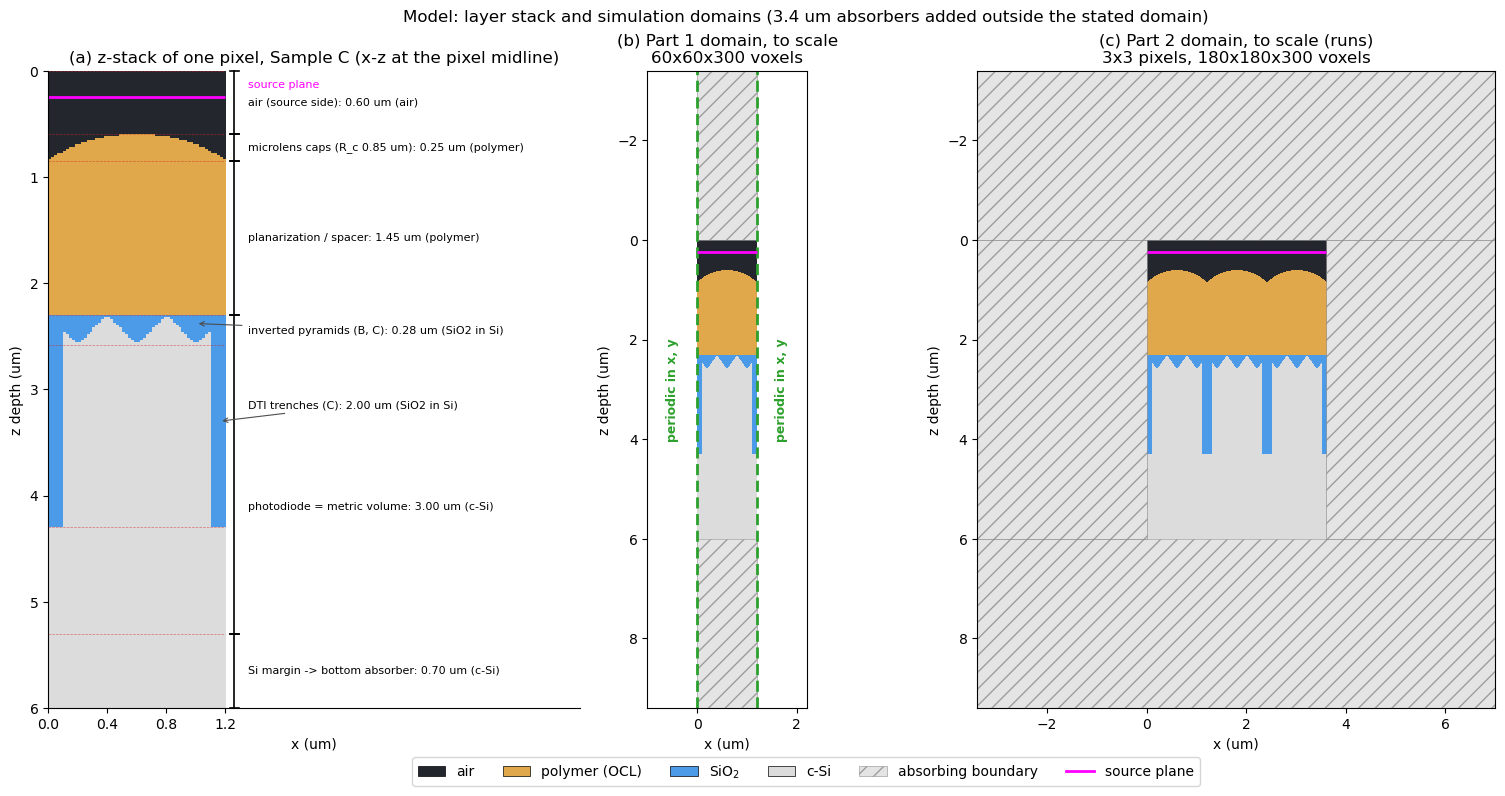

In [12]:
# z-stack of one pixel with layer thicknesses, next to both simulation domains drawn to scale
eps_px, nxy_px, iy_px = build(PREVIEW_SAMPLE, 1)
lab_px = material_labels(eps_px[:, iy_px, :])            # (x, z) material map, pixel midline
W, H, bw = nxy_px * pixel_size, nz * pixel_size, boundary_um
MAT_KW = dict(origin="upper", cmap=MAT_CMAP, norm=MAT_NORM, interpolation="nearest")
HATCH = dict(facecolor="0.85", edgecolor="0.5", hatch="//", alpha=0.7, lw=0.5)

fig, axes = plt.subplots(1, 3, figsize=(16, 7.5), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.6, 0.8, 2.2]})

# (a) one pixel, every layer labelled with its thickness
ax = axes[0]
ax.imshow(lab_px.T, extent=[0, W, H, 0], aspect="auto", **MAT_KW)
label_z = {"air (source side)": 0.30, "planarization / spacer": 1.57,
           "inverted pyramids (B, C)": 2.45, "DTI trenches (C)": 3.15,
           "photodiode = metric volume": 4.10, "Si margin -> bottom absorber": 5.65}
points_at = {"inverted pyramids (B, C)": (W * 5 / 6, z_si0 + 0.08),   # a pyramid pit
             "DTI trenches (C)": (W - 0.04, z_si0 + 1.0)}             # the half-trench at the border
xt = W + 0.15
for name, a, b, mat in stack:
    zt = label_z.get(name, (a + b) / 2)
    text = f"{name}: {b - a:.2f} um ({mat})"
    if name in points_at:
        ax.annotate(text, xy=points_at[name], xytext=(xt, zt), fontsize=8, va="center",
                    arrowprops=dict(arrowstyle="->", color="0.3", lw=0.8), annotation_clip=False)
    else:
        ax.plot([W + 0.06] * 2, [a, b], color="k", lw=1.2, clip_on=False)
        for z in (a, b):
            ax.plot([W + 0.03, W + 0.09], [z, z], color="k", lw=1.2, clip_on=False)
        ax.text(xt, zt, text, fontsize=8, va="center")
for z in sorted({z for _, a, b, _ in stack for z in (a, b)}):
    ax.hlines(z, 0, W, color="tab:red", lw=0.5, ls="--", alpha=0.6)
ax.hlines(z_src, 0, W, color="magenta", lw=2)
ax.text(xt, z_src - 0.12, "source plane", color="magenta", fontsize=8, va="center")
ax.set_xlim(0, W + 2.4)
ax.set_xticks(np.round(np.linspace(0, W, 4), 2))
ax.set_ylim(H, 0)
ax.set(title=f"(a) z-stack of one pixel, Sample {PREVIEW_SAMPLE} (x-z at the pixel midline)",
       xlabel="x (um)", ylabel="z depth (um)")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)


def domain(ax, lab, width, periodic_xy, title):
    ax.imshow(lab.T, extent=[0, width, H, 0], aspect="equal", **MAT_KW)
    for z0 in (-bw, H):                                       # absorbers above and below
        ax.add_patch(Rectangle((-(0 if periodic_xy else bw), z0),
                               width + (0 if periodic_xy else 2 * bw), bw, **HATCH))
    if periodic_xy:
        for x, xt_ in ((0, -0.5), (width, width + 0.5)):
            ax.axvline(x, color="tab:green", lw=2, ls=(0, (4, 2)))
            ax.text(xt_, H / 2, "periodic in x, y", color="tab:green", rotation=90,
                    ha="center", va="center", fontsize=9, fontweight="bold")
        ax.set_xlim(-1.0, width + 1.0)
    else:
        for x0 in (-bw, width):                               # absorbers on the sides too
            ax.add_patch(Rectangle((x0, 0), bw, H, **HATCH))
        ax.set_xlim(-bw, width + bw)
    ax.hlines(z_src, 0, width, color="magenta", lw=2)
    ax.set_ylim(H + bw, -bw)
    ax.set(title=title, xlabel="x (um)", ylabel="z depth (um)")


n1 = npp
domain(axes[1], lab_px, W, True,
       f"(b) Part 1 domain, to scale\n{n1}x{n1}x{nz} voxels")
n2 = N_PIX_XTALK * npp
domain(axes[2], np.tile(lab_px, (N_PIX_XTALK, 1)), N_PIX_XTALK * W, False,
       f"(c) Part 2 domain, to scale ({'runs' if RUN_CROSSTALK else 'disabled'})\n"
       f"{N_PIX_XTALK}x{N_PIX_XTALK} pixels, {n2}x{n2}x{nz} voxels")
fig.legend(handles=MAT_LEGEND + [Patch(label="absorbing boundary", **HATCH),
                                 plt.Line2D([], [], color="magenta", lw=2, label="source plane")],
           loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.05))
fig.suptitle(f"Model: layer stack and simulation domains ({boundary_um} um absorbers added "
             "outside the stated domain)", fontsize=12)
plt.show()

### 6.2 Materials
The four materials, their complex index n, the permittivity ε = n² the solver receives, and where each is used. Only Si absorbs (Im ε > 0), so all absorbed power is counted in the photodiode. The chart after the printout shows the same values, in the colours used by the material maps in 6.4–6.6.

In [13]:
uses = ["incidence medium above the lenses; source plane sits here",
        "on-chip microlens caps + planarization / filter spacer",
        "pyramid backfill (B, C) and DTI trench fill (C)",
        "photodiode (absorbing)"]
print(f"{'material':<15}{'n':>21}{'eps = n^2':>23}   used for")
for name, n_val, use in zip(MATERIAL_NAMES, MATERIAL_N, uses):
    n_c = complex(n_val)
    e_c = n_c ** 2
    print(f"{name.replace('$_2$', '2'):<15}{n_c.real:9.4f} {n_c.imag:+.5f}j"
          f"{e_c.real:9.4f} {e_c.imag:+.5f}j   {use}")

alpha = 4 * np.pi * n_si.imag / wavelength      # intensity absorption coefficient (1/um)
print(f"\nSi absorption depth 1/alpha = {1/alpha:.1f} um at {wavelength*1e3:.0f} nm -> a single "
      f"pass through {si_thick} um absorbs only {(1-np.exp(-alpha*si_thick))*100:.1f}% "
      "(before reflection losses).")
print("That weak absorption is why light trapping by the pyramids matters.")

material                           n              eps = n^2   used for
air               1.0000 +0.00000j   1.0000 +0.00000j   incidence medium above the lenses; source plane sits here
polymer (OCL)     1.6000 +0.00000j   2.5600 +0.00000j   on-chip microlens caps + planarization / filter spacer
SiO2              1.4500 +0.00000j   2.1025 +0.00000j   pyramid backfill (B, C) and DTI trench fill (C)
c-Si              3.6530 +0.00362j  13.3444 +0.02645j   photodiode (absorbing)

Si absorption depth 1/alpha = 18.7 um at 850 nm -> a single pass through 3.0 um absorbs only 14.8% (before reflection losses).
That weak absorption is why light trapping by the pyramids matters.


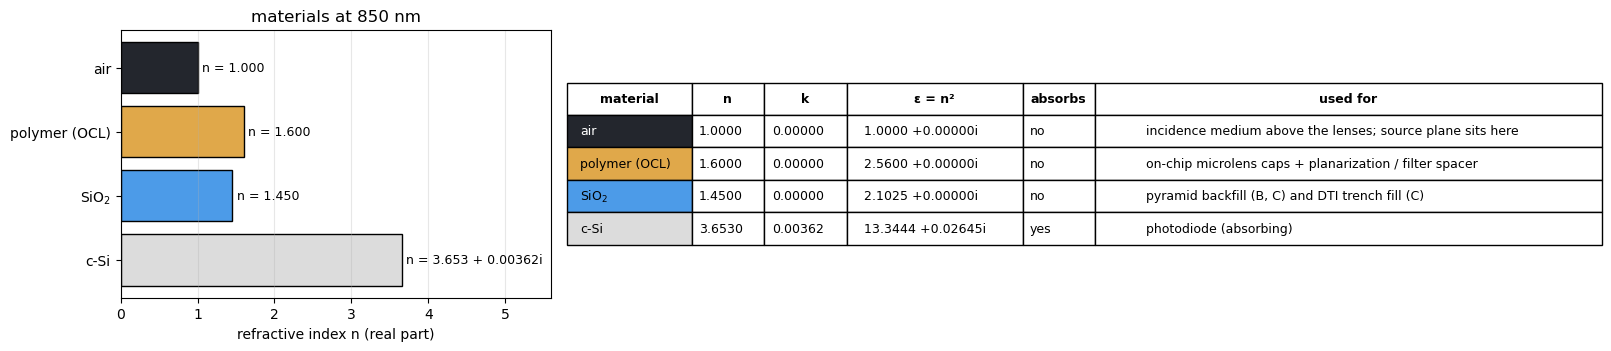

In [14]:
# material chart: the same values, in the colours used by the material maps below
fig, (axb, axt) = plt.subplots(1, 2, figsize=(16, 3.4), constrained_layout=True,
                               gridspec_kw={"width_ratios": [1, 2.4]})
n_c = [complex(v) for v in MATERIAL_N]
axb.barh(range(len(n_c)), [v.real for v in n_c], color=MATERIAL_COLORS, edgecolor="k")
for i, v in enumerate(n_c):
    axb.text(v.real + 0.06, i, f"n = {v.real:.3f}" + (f" + {v.imag:.5f}i" if v.imag else ""),
             va="center", fontsize=9)
axb.set_yticks(range(len(n_c)), MATERIAL_NAMES)
axb.invert_yaxis()
axb.set_xlim(0, 5.6)
axb.set(xlabel="refractive index n (real part)", title=f"materials at {wavelength*1e3:.0f} nm")
axb.grid(axis="x", alpha=0.3)

axt.axis("off")
rows = [[name, f"{v.real:.4f}", f"{v.imag:.5f}", f"{(v**2).real:.4f} {(v**2).imag:+.5f}i",
         "yes" if v.imag > 0 else "no", use]
        for name, v, use in zip(MATERIAL_NAMES, n_c, uses)]
tbl = axt.table(cellText=rows, colLabels=["material", "n", "k", "ε = n²", "absorbs", "used for"],
                colWidths=[0.12, 0.07, 0.08, 0.17, 0.07, 0.49], loc="center", cellLoc="left")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.9)
for i, col in enumerate(MATERIAL_COLORS, start=1):            # colour swatch = material colour
    tbl[i, 0].set_facecolor(col)
    tbl[i, 0].get_text().set_color("white" if i == 1 else "black")
for j in range(6):
    tbl[0, j].set_text_props(fontweight="bold")
plt.show()

### 6.3 Structure — overview
Four views of the medium that `build(PREVIEW_SAMPLE, PREVIEW_N_PIX)` creates, shaded by refractive index (dark = air, gray = polymer / SiO₂, white = Si):
* **top-left:** top view (x-y) cut through the microlens caps;
* **top-right:** side view (y-z) through the centre-pixel midline;
* **bottom-left:** side view (x-z) through the centre-pixel midline (the same row the `xz_slice` monitor returns);
* **bottom-right:** 3D cut-away of the array (front half removed).

Dashed lines show where the other cuts are taken.

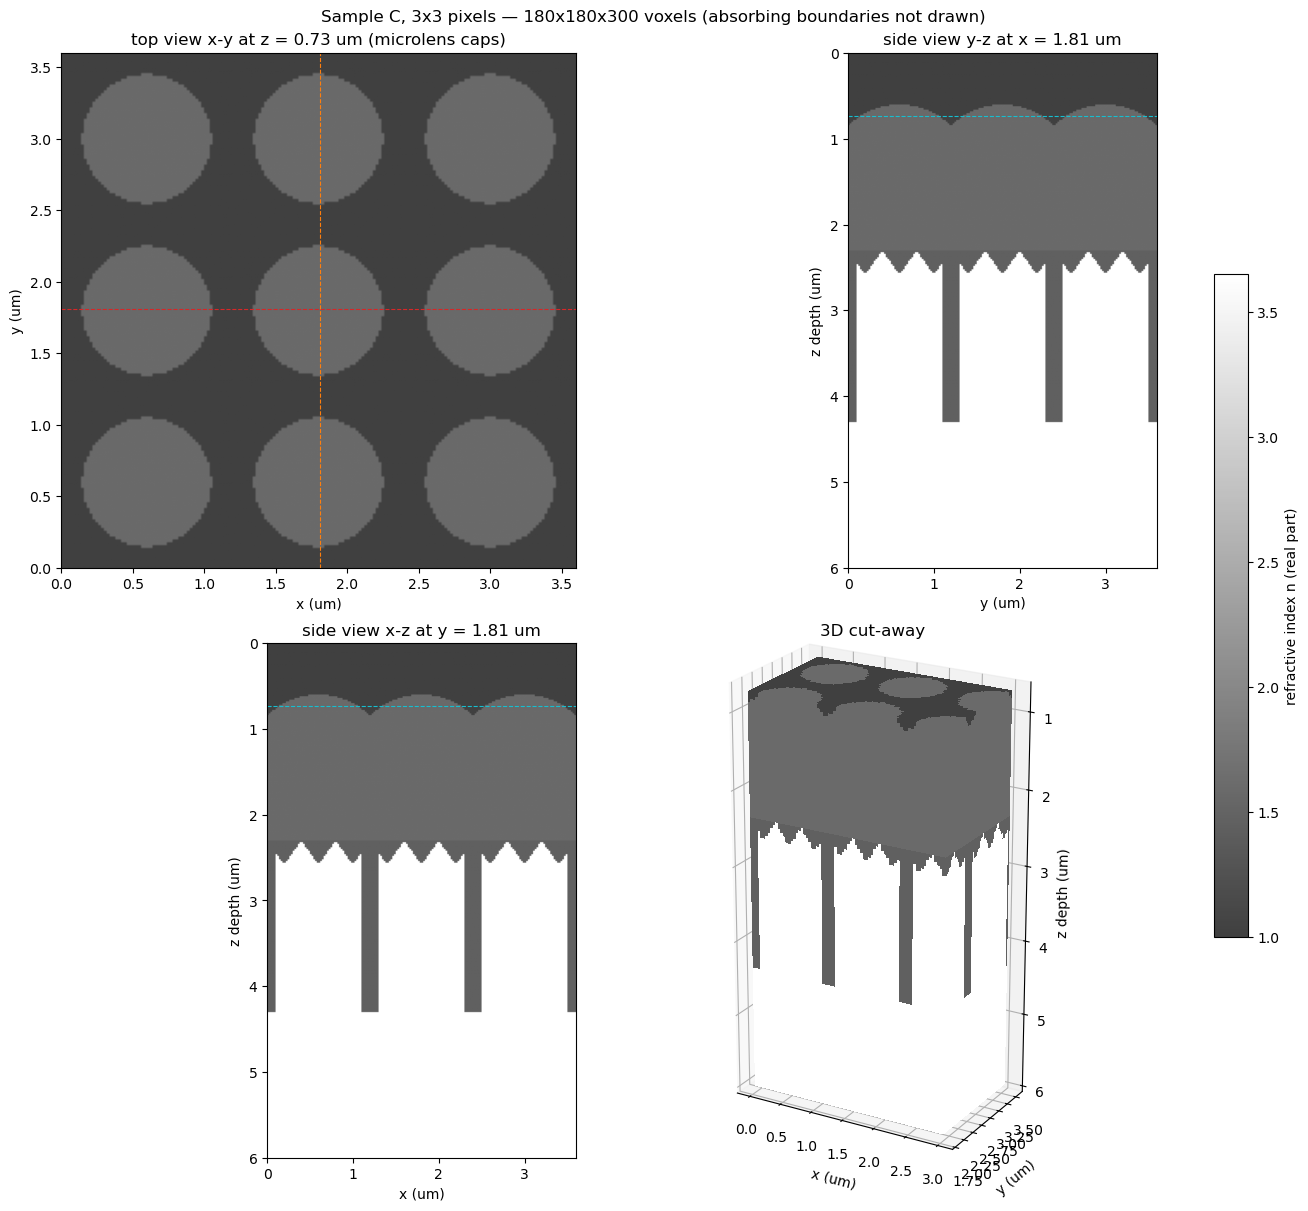

In [15]:
eps_prev, nxy_prev, _ = build(PREVIEW_SAMPLE, PREVIEW_N_PIX)
L_prev = nxy_prev * pixel_size
Z_END = nz * pixel_size
ix_mid = iy_mid = nxy_prev // 2                       # centre-pixel midline (an apex row)
iz_lens = int(round((z_vertex + 0.5 * sag) / pixel_size))   # cut through the lens caps


def n_of(e):
    return np.sqrt(e).real                            # real refractive index for display


LIGHT_GRAY = ListedColormap(plt.get_cmap("gray")(np.linspace(0.25, 1.0, 256)))  # starts at mid-dark gray, not black
N_KW = dict(cmap=LIGHT_GRAY, vmin=n_air, vmax=n_si.real)
x_c = (ix_mid + 0.5) * pixel_size
y_c = (iy_mid + 0.5) * pixel_size
z_l = (iz_lens + 0.5) * pixel_size

fig = plt.figure(figsize=(13, 12), constrained_layout=True)
ax = fig.add_subplot(2, 2, 1)
im = ax.imshow(n_of(eps_prev[:, :, iz_lens]).T, origin="lower",
               extent=[0, L_prev, 0, L_prev], **N_KW)
ax.axhline(y_c, color="tab:red", ls="--", lw=0.8)
ax.axvline(x_c, color="tab:orange", ls="--", lw=0.8)
ax.set(title=f"top view x-y at z = {z_l:.2f} um (microlens caps)",
       xlabel="x (um)", ylabel="y (um)")

ax = fig.add_subplot(2, 2, 2)
ax.imshow(n_of(eps_prev[ix_mid, :, :]).T, origin="upper",
          extent=[0, L_prev, Z_END, 0], **N_KW)
ax.axhline(z_l, color="tab:cyan", ls="--", lw=0.8)
ax.set(title=f"side view y-z at x = {x_c:.2f} um", xlabel="y (um)", ylabel="z depth (um)")

ax = fig.add_subplot(2, 2, 3)
ax.imshow(n_of(eps_prev[:, iy_mid, :]).T, origin="upper",
          extent=[0, L_prev, Z_END, 0], **N_KW)
ax.axhline(z_l, color="tab:cyan", ls="--", lw=0.8)
ax.set(title=f"side view x-z at y = {y_c:.2f} um", xlabel="x (um)", ylabel="z depth (um)")

# 3D cut-away: block x in [0, xR], y in [y_c, L], z in [z_l, Z_END]
ax = fig.add_subplot(2, 2, 4, projection="3d")
s = 2                                                  # plot every 2nd voxel
xv = (np.arange(nxy_prev) + 0.5) * pixel_size
zv = (np.arange(nz) + 0.5) * pixel_size
ixR = nxy_prev - npp // 2                              # centre of the last pixel column
xs, ys, zs = np.arange(0, ixR + 1, s), np.arange(iy_mid, nxy_prev, s), np.arange(iz_lens, nz, s)
nrm = lambda v: LIGHT_GRAY((v - N_KW["vmin"]) / (N_KW["vmax"] - N_KW["vmin"]))


def face(X, Y, Z, vals):
    X, Y, Z = (np.broadcast_to(a, vals.shape) for a in (X, Y, Z))
    ax.plot_surface(X, Y, -Z, facecolors=nrm(vals), rstride=1, cstride=1,
                    shade=False, linewidth=0, antialiased=False)


face(xv[xs][:, None], y_c, zv[zs][None, :], n_of(eps_prev[xs][:, iy_mid][:, zs]))      # front
face(xv[ixR], xv[ys][:, None], zv[zs][None, :], n_of(eps_prev[ixR][ys][:, zs]))       # right
face(xv[xs][:, None], xv[ys][None, :], z_l, n_of(eps_prev[xs][:, ys, iz_lens]))       # top
ax.set_box_aspect((xv[ixR], L_prev - y_c, Z_END - z_l))
ax.set(xlabel="x (um)", ylabel="y (um)", zlabel="z depth (um)", title="3D cut-away")
ax.zaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{-v:.0f}"))
ax.view_init(elev=22, azim=-60)

fig.colorbar(im, ax=fig.axes[:3], shrink=0.6, label="refractive index n (real part)")
fig.suptitle(f"Sample {PREVIEW_SAMPLE}, {PREVIEW_N_PIX}x{PREVIEW_N_PIX} pixels — "
             f"{nxy_prev}x{nxy_prev}x{nz} voxels (absorbing boundaries not drawn)", fontsize=12)
plt.show()

### 6.4 Structure — layer by layer (top views)
Material map at three depths: through the microlenses, just below the Si surface (pyramid mouths + trench grid), and 1 μm into the Si (below the pyramid tips, where only the trenches remain).

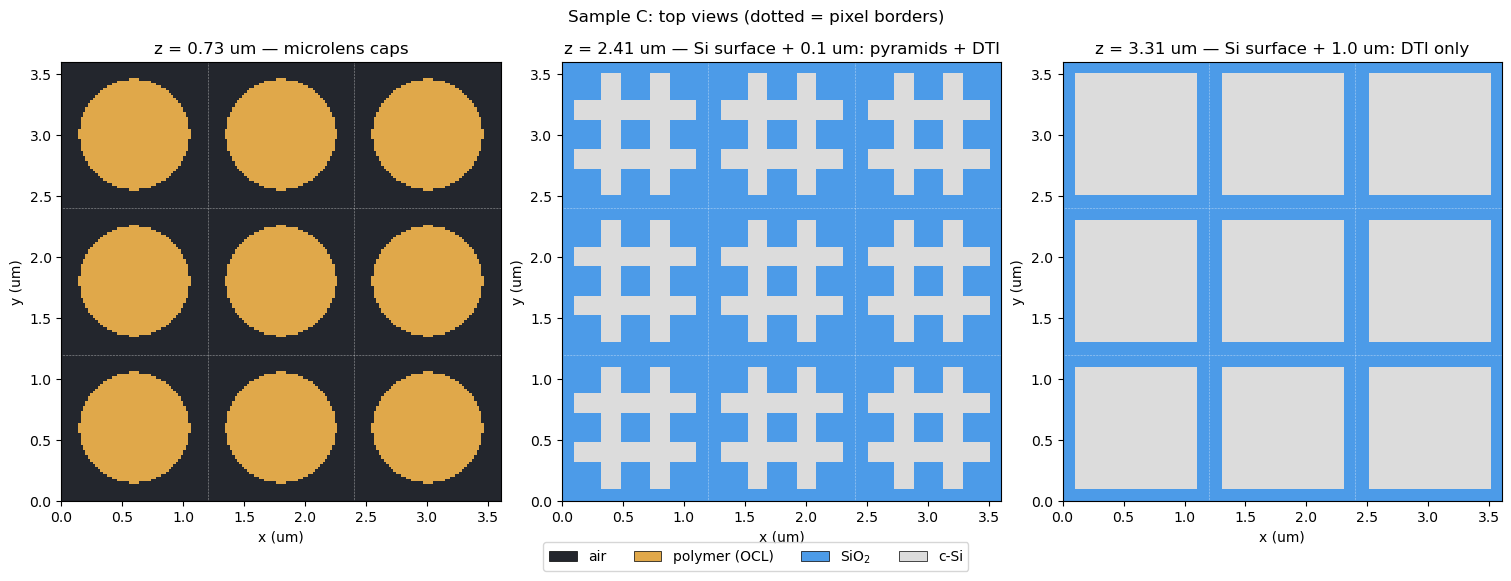

In [16]:
cuts = [(iz_lens, "microlens caps"),
        (iz_si0 + int(round(0.1 / pixel_size)), "Si surface + 0.1 um: pyramids + DTI"),
        (iz_si0 + int(round(1.0 / pixel_size)), "Si surface + 1.0 um: DTI only")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), constrained_layout=True)
for ax, (iz, what) in zip(axes, cuts):
    ax.imshow(material_labels(eps_prev[:, :, iz]).T, origin="lower", cmap=MAT_CMAP,
              norm=MAT_NORM, extent=[0, L_prev, 0, L_prev], interpolation="nearest")
    for k in range(1, PREVIEW_N_PIX):
        ax.axvline(k * pix, color="w", lw=0.4, ls=":")
        ax.axhline(k * pix, color="w", lw=0.4, ls=":")
    ax.set(title=f"z = {(iz + 0.5) * pixel_size:.2f} um — {what}",
           xlabel="x (um)", ylabel="y (um)")
fig.legend(handles=MAT_LEGEND, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"Sample {PREVIEW_SAMPLE}: top views (dotted = pixel borders)", fontsize=12)
plt.show()

### 6.5 Structure — samples A, B, C compared (one pixel)
The Part 1 unit cell for each sample: an x-z cut through the pixel midline. Only the Si surface changes between samples. The lines mark the layer boundaries from 6.1.

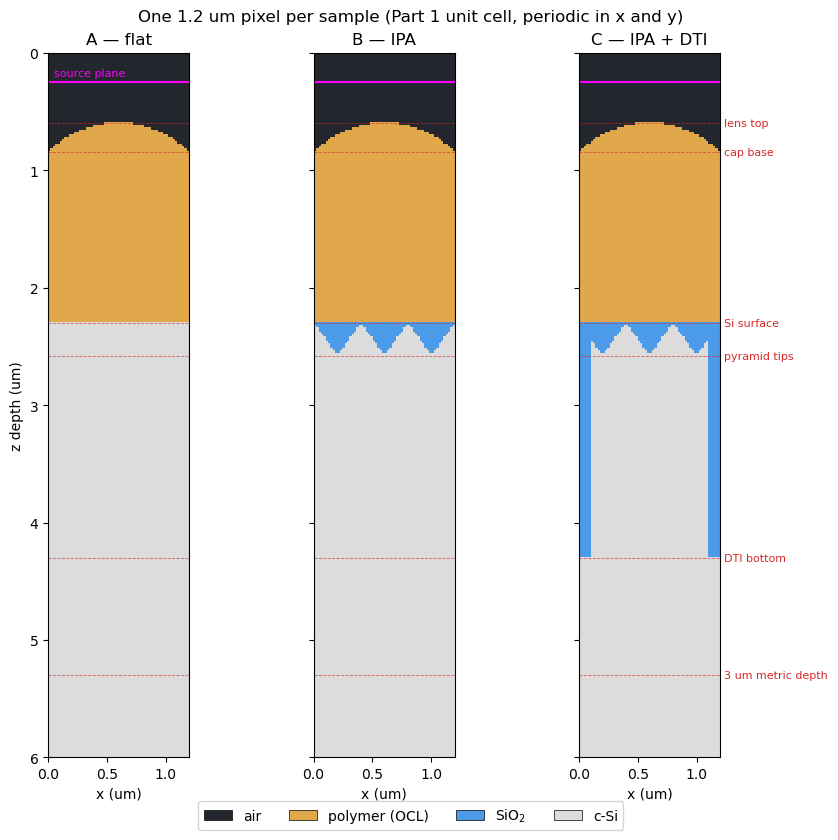

In [17]:
marks = [(z_vertex, "lens top"), (z_vertex + sag, "cap base"), (z_si0, "Si surface"),
         (z_si0 + pyr_depth, "pyramid tips"), (z_si0 + dti_depth, "DTI bottom"),
         (z_si0 + si_thick, "3 um metric depth")]
fig, axes = plt.subplots(1, 3, figsize=(8.5, 8), constrained_layout=True, sharey=True)
for ax, sample in zip(axes, SAMPLES):
    eps1, nxy_1, iy1 = build(sample, 1)
    ax.imshow(material_labels(eps1[:, iy1, :]).T, origin="upper", cmap=MAT_CMAP, norm=MAT_NORM,
              extent=[0, nxy_1 * pixel_size, Z_END, 0], interpolation="nearest")
    for zm, lab in marks:
        ax.axhline(zm, color="tab:red", lw=0.6, ls="--", alpha=0.7)
        if sample == SAMPLES[-1]:
            ax.text(nxy_1 * pixel_size * 1.03, zm, lab, va="center", fontsize=8, color="tab:red")
    ax.axhline(z_src, color="magenta", lw=1.5)
    ax.set(title={"A": "A — flat", "B": "B — IPA", "C": "C — IPA + DTI"}[sample],
           xlabel="x (um)")
axes[0].set_ylabel("z depth (um)")
axes[0].text(0.05, z_src - 0.05, "source plane", color="magenta", fontsize=8)
fig.legend(handles=MAT_LEGEND, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"One {pix} um pixel per sample (Part 1 unit cell, periodic in x and y)", fontsize=12)
plt.show()

### 6.6 Sources, monitors and boundaries
* **(a)** Part 1 plane wave: uniform amplitude over the periodic cell, polarized along x.
* **(b)** Part 2 Gaussian beam over the `N_PIX_XTALK × N_PIX_XTALK` array: only the centre lens is lit. The circle marks the amplitude half-maximum.
* **(c)** Gaussian profile along x through the centre. The share of source power falling outside the centre pixel explains the flat-sample (A) crosstalk baseline.
* **(d)** Part 2 side view with everything the solver will see: source plane, the two monitors (the returned regions), and the absorbing boundaries it adds outside the domain (hatched).

Part 1 source: plane wave, x-polarized, plane z = 0.24 um (voxel 12), 60x60 voxels, |amplitude| = 1.00
Part 2 source: Gaussian beam, x-polarized, same plane, 180x180 voxels, sigma = 510 nm, amplitude FWHM = 1.2 um
               81.7% of the source power lies over the centre pixel, 18.3% over the neighbours


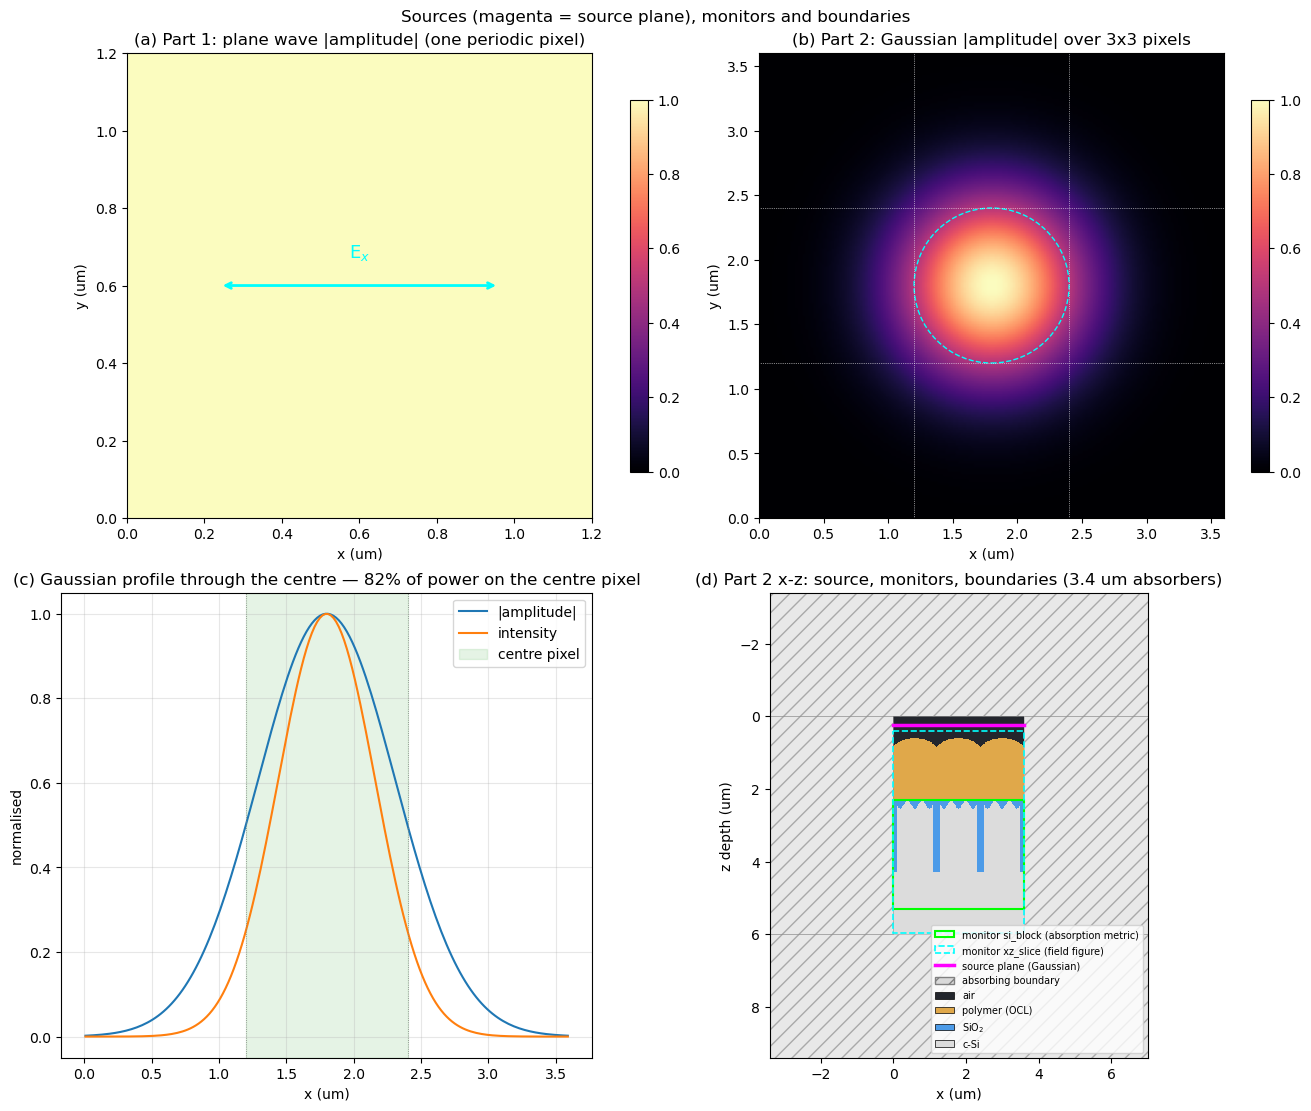

Part 1 uses the same z layout, but x and y are PERIODIC: absorbers are added only above and below.


In [18]:
pw_amp = np.abs(pw_values[0, :, :, 0])
gb_amp = np.abs(gb_prev_values[0, :, :, 0])
pol = "xyz"[pw_position[0]]
L2 = nxy2_prev * pixel_size
cpx_prev = n_pix_prev2 // 2
c0, c1 = cpx_prev * npp, (cpx_prev + 1) * npp
p_in = (gb_amp[c0:c1, c0:c1] ** 2).sum() / (gb_amp ** 2).sum()

print(f"Part 1 source: plane wave, {pol}-polarized, plane z = {pw_position[3]*pixel_size:.2f} um "
      f"(voxel {pw_position[3]}), {pw_amp.shape[0]}x{pw_amp.shape[1]} voxels, |amplitude| = {pw_amp.max():.2f}")
print(f"Part 2 source: Gaussian beam, {'xyz'[gb_prev_position[0]]}-polarized, same plane, "
      f"{gb_amp.shape[0]}x{gb_amp.shape[1]} voxels, sigma = {sigma_px_prev*pixel_size*1e3:.0f} nm, "
      f"amplitude FWHM = {pix} um")
print(f"               {p_in*100:.1f}% of the source power lies over the centre pixel, "
      f"{(1-p_in)*100:.1f}% over the neighbours")

fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
ax = axes[0, 0]
L1 = pw_amp.shape[0] * pixel_size
im = ax.imshow(pw_amp.T, origin="lower", extent=[0, L1, 0, L1], cmap="magma", vmin=0, vmax=1)
ax.annotate("", xy=(0.8 * L1, 0.5 * L1), xytext=(0.2 * L1, 0.5 * L1),
            arrowprops=dict(arrowstyle="<->", color="cyan", lw=2))
ax.text(0.5 * L1, 0.56 * L1, f"E$_{pol}$", color="cyan", ha="center", fontsize=13)
ax.set(title="(a) Part 1: plane wave |amplitude| (one periodic pixel)",
       xlabel="x (um)", ylabel="y (um)")
fig.colorbar(im, ax=ax, shrink=0.8)

ax = axes[0, 1]
im = ax.imshow(gb_amp.T, origin="lower", extent=[0, L2, 0, L2], cmap="magma", vmin=0, vmax=1)
for k in range(1, n_pix_prev2):
    ax.axvline(k * pix, color="w", lw=0.5, ls=":")
    ax.axhline(k * pix, color="w", lw=0.5, ls=":")
ax.add_patch(Circle((L2 / 2, L2 / 2), pix / 2, fill=False, color="cyan", ls="--"))
ax.set(title=f"(b) Part 2: Gaussian |amplitude| over {n_pix_prev2}x{n_pix_prev2} pixels",
       xlabel="x (um)", ylabel="y (um)")
fig.colorbar(im, ax=ax, shrink=0.8)

ax = axes[1, 0]
xg = (np.arange(nxy2_prev) + 0.5) * pixel_size
row = gb_amp[:, nxy2_prev // 2]
ax.plot(xg, row, label="|amplitude|")
ax.plot(xg, row ** 2, label="intensity")
ax.axvspan(c0 * pixel_size, c1 * pixel_size, color="tab:green", alpha=0.12, label="centre pixel")
for k in range(1, n_pix_prev2):
    ax.axvline(k * pix, color="gray", lw=0.6, ls=":")
ax.set(title=f"(c) Gaussian profile through the centre — {p_in*100:.0f}% of power on the centre pixel",
       xlabel="x (um)", ylabel="normalised")
ax.grid(alpha=0.3)
ax.legend()

ax = axes[1, 1]
eps2, _, _ = build(PREVIEW_SAMPLE, n_pix_prev2)
ax.imshow(material_labels(eps2[:, nxy2_prev // 2, :]).T, origin="upper", cmap=MAT_CMAP,
          norm=MAT_NORM, extent=[0, L2, Z_END, 0], interpolation="nearest")
del eps2
b = boundary_um
for (x0, z0, w, h) in [(-b, -b, L2 + 2 * b, b), (-b, Z_END, L2 + 2 * b, b),
                       (-b, 0, b, Z_END), (L2, 0, b, Z_END)]:
    ax.add_patch(Rectangle((x0, z0), w, h, facecolor="0.85", edgecolor="0.5",
                           hatch="//", alpha=0.6, lw=0.5))
ax.add_patch(Rectangle((0, iz_si0 * pixel_size), L2, M_SI * pixel_size, fill=False,
                       ec="lime", lw=1.5, label="monitor si_block (absorption metric)"))
ax.add_patch(Rectangle((0, IZ_SLICE0 * pixel_size), L2, M_SLICE * pixel_size, fill=False,
                       ec="cyan", lw=1.2, ls="--", label="monitor xz_slice (field figure)"))
ax.plot([0, L2], [z_src, z_src], color="magenta", lw=2.5, label="source plane (Gaussian)")
ax.set_xlim(-b, L2 + b)
ax.set_ylim(Z_END + b, -b)
ax.set_aspect("equal")
ax.set(title=f"(d) Part 2 x-z: source, monitors, boundaries ({boundary_um} um absorbers)",
       xlabel="x (um)", ylabel="z depth (um)")
bnd = Patch(facecolor="0.85", edgecolor="0.5", hatch="//", label="absorbing boundary")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [bnd] + MAT_LEGEND,
          fontsize=7, loc="lower right")
fig.suptitle("Sources (magenta = source plane), monitors and boundaries", fontsize=12)
plt.show()
print("Part 1 uses the same z layout, but x and y are PERIODIC: absorbers are added only above and below.")

## 7. Run Part 1 — sensitivity
One periodic pixel under uniform illumination: a 60×60×300-voxel domain without boundaries. First an air-only reference run calibrates the incident |E₀|². Then each sample is solved and its absorbed fraction A and FOM = A / A_flat are printed.

Expected: A = 11.7 %, B = 14.4 % (FOM 1.24), C = 15.0 % (FOM 1.29).

In [19]:
k0 = 2 * np.pi / wavelength

In [20]:
print(f"PART 1 — periodic pixel, uniform illumination, lambda = {wavelength*1e3:.0f} nm")

# |E0|² calibration: identical source in a uniform-air domain (incidence medium).
eps_air = np.full((nxy1, nxy1, nz), n_air ** 2, dtype=np.complex64)
esq_ref, _, _, _ = solve(eps_air, nxy1, (pw_values, pw_position), (True, True, False))
e0sq = float(esq_ref.mean())

part1 = {}      # sample -> absorbed fraction
slices1 = {}    # sample -> |E| viz slice
for sample in SAMPLES:
    permittivity, nxy, _ = build(sample, 1)
    start = time()
    esq_si, mag, iters, res = solve(permittivity, nxy, (pw_values, pw_position),
                                    (True, True, False))
    A = k0 * pixel_size * absorbed_density(esq_si, permittivity).sum() \
        / (n_air * e0sq * nxy * nxy)
    part1[sample] = A
    slices1[sample] = mag
    fom = A / part1["A"]
    print(f"  Sample {sample}:  A = {A*100:5.2f}%   FOM = {fom:4.2f}   "
          f"({iters} iters, res {res:.1e}, {time()-start:.1f} s)")
print("  (Simplified model — perfect absorber below the photodiode, no AR layer,"
      " no color filters: figures describe this model, not the physical device.)")

PART 1 — periodic pixel, uniform illumination, lambda = 850 nm

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 2e49fbcb-2eff-4792-8478-072cca5ffdd4
  Version   : 4adb2ca3-0450-48ac-b996-f5bd0031076c
  Command   : 8e201117-c1c7-4252-87d0-c35daf1e2a62
  Mode      : Maxwell (vectorial)
  Domain    : 60x60x300 voxels  lambda=0.85 um  dx=0.020 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : f1213ca2-fc69-4a72-8cfc-3f79e10fe66a
  Version   : b43b984d-81ca-4157-8cf6-f0dbd9f60a8a
  Command   : 7710542d-6c22-47ef-a01d-b212371affc4
  Mode      : Maxwell (vectorial)
  Domain    : 60x60x300 voxels  lambda=0.85 um  dx=0.020 um
  Engine    : An

## 8. Run Part 2 — optical crosstalk
Runs only when `RUN_CROSSTALK = True` (section 2.1). An `N_PIX_XTALK × N_PIX_XTALK` array with absorbing side boundaries, lit on the centre pixel only. The absorbed power is summed per photodiode. The default 3×3 array is 180×180×300 voxels without boundaries; with `N_PIX_XTALK = 5` it is 300×300×300 voxels, 262.1 Mvoxel including the absorbing boundaries the solver adds outside it (section 6.1 prints these sizes for the current settings).

Expected neighbour-total / centre at 3×3: 41.3 % (A), 100.1 % (B), 46.2 % (C). At 5×5: 45.0 % (A), 130.3 % (B), 53.7 % (C). A's share comes mostly from the Gaussian illumination tails and is the unavoidable baseline.

* **Second ring (5×5 only):** B leaks well into it, up to 5.8 % of the centre signal two pixels away, while C's second ring stays near the flat baseline. This is what the larger array adds.
* **Consistency check:** the central 3×3 block does not depend on the array size.

In [21]:
signals = {}    # sample -> n_pix x n_pix absorbed-power matrix
slices2 = {}    # sample -> |E| viz slice through the centre-pixel midline
if RUN_CROSSTALK:
    n_pix = N_PIX_XTALK
    cpx = n_pix // 2                # centre-pixel index
    nxy2 = n_pix * npp
    # Apodized Gaussian on the centre lens, FWHM = one pixel: neighbours receive
    # essentially no direct light, so any neighbour signal IS optical crosstalk.
    sigma_px = (pix / pixel_size) / 2.3548          # FWHM = one pixel pitch
    gb_values, gb_position = gaussian_beam(
        shape=[(nxy2 + 0.5) * pixel_size] * 2, origin="topleft",
        position=[0, 0.0, 0.0, z_src], source_plane="xy",
        pixel_size=pixel_size, waist=np.sqrt(2) * sigma_px * pixel_size)  # w0 = sqrt(2) sigma, μm

    print(f"\nPART 2 — {n_pix}x{n_pix} pixels, centre-only Gaussian (FWHM = {pix} um), "
          f"absorbing boundaries")
    print(f"  stated domain {nxy2}x{nxy2}x{nz} voxels; solver adds ~{boundary_um} um "
          f"absorbers on all six faces")
    for sample in SAMPLES:
        permittivity, nxy, _ = build(sample, n_pix)
        start = time()
        esq_si, mag, iters, res = solve(permittivity, nxy, (gb_values, gb_position),
                                        (False, False, False))
        dens = absorbed_density(esq_si, permittivity)
        # per-pixel absorbed power: fold the (nxy, nxy) plane into n_pix x n_pix pixels
        s = dens.reshape(n_pix, npp, n_pix, npp, n_metric).sum(axis=(1, 3, 4))
        signals[sample] = s
        slices2[sample] = mag
        xtalk = (s.sum() - s[cpx, cpx]) / s[cpx, cpx] * 100
        print(f"  Sample {sample}:  centre signal {s[cpx, cpx]:.3e}   "
              f"neighbour total = {xtalk:5.1f}% of centre   "
              f"({iters} iters, res {res:.1e}, {time()-start:.1f} s)")
    b, c = signals.get("B"), signals.get("C")
    if b is not None and c is not None:
        print(f"  DTI effect: neighbour/centre  B = "
              f"{(b.sum()-b[cpx,cpx])/b[cpx,cpx]*100:.1f}%  ->  C = "
              f"{(c.sum()-c[cpx,cpx])/c[cpx,cpx]*100:.1f}%   (same centre-pixel gain kept)")


PART 2 — 3x3 pixels, centre-only Gaussian (FWHM = 1.2 um), absorbing boundaries
  stated domain 180x180x300 voxels; solver adds ~3.4 um absorbers on all six faces

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : cd5d3923-9d55-49f9-b8e3-3aa78886c41e
  Version   : 3bbc8fe0-b9e4-45d7-9f76-61c1d6d6a467
  Command   : f93b83ab-fc53-4526-9506-d018e4327ab5
  Mode      : Maxwell (vectorial)
  Domain    : 180x180x300 voxels  lambda=0.85 um  dx=0.020 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  Sample A:  centre signal 2.024e-03   neighbour total =  41.4% of centre   (1663 iters, res 9.9e-07, 704.6 s)

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : bd2cf2fa-e575-4e1c-994b-247d66dd514

## 9. Results
### Figure 1 — Part 1: field slices + absorption / FOM bars

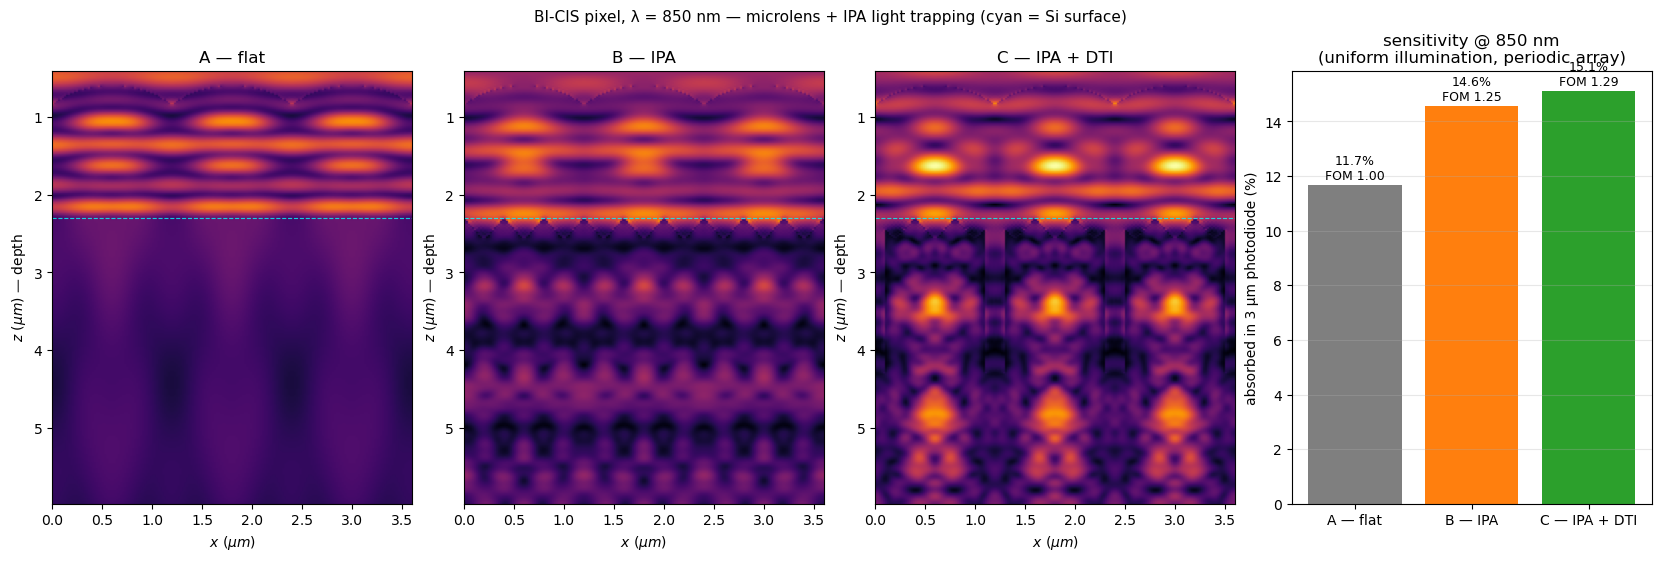

In [22]:
z0, z1 = IZ_SLICE0 * pixel_size, (IZ_SLICE0 + M_SLICE) * pixel_size
vmax1 = max(m.max() for m in slices1.values())
fig, axes = plt.subplots(1, len(SAMPLES) + 1, figsize=(4 * len(SAMPLES) + 4.5, 5.5),
                         constrained_layout=True)
titles = {"A": "A — flat", "B": "B — IPA", "C": "C — IPA + DTI"}
for ax, sample in zip(axes[:-1], SAMPLES):
    mag = np.tile(slices1[sample], (3, 1))          # show 3 periods
    extent = [0, 3 * pix, z1, z0]
    ax.imshow(mag.T, cmap="inferno", extent=extent, vmin=0, vmax=vmax1, aspect="auto")
    ax.axhline(z_si0, color="cyan", lw=0.8, ls="--", alpha=0.8)
    ax.set_title(titles[sample])
    ax.set_xlabel(r"$x~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$ — depth")
ax = axes[-1]
vals = [part1[s] * 100 for s in SAMPLES]
bars = ax.bar([titles[s] for s in SAMPLES], vals,
              color=["tab:gray", "tab:orange", "tab:green"])
for bar, s in zip(bars, SAMPLES):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            f"{part1[s]*100:.1f}%\nFOM {part1[s]/part1['A']:.2f}",
            ha="center", fontsize=9)
ax.set_ylabel("absorbed in 3 μm photodiode (%)")
ax.set_title("sensitivity @ 850 nm\n(uniform illumination, periodic array)")
ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("BI-CIS pixel, λ = 850 nm — microlens + IPA light trapping "
             "(cyan = Si surface)", fontsize=11)
fig.savefig(f"{OUTPUT_DIR}/mx_ipa_pixel_sensitivity.png", dpi=300,
            bbox_inches="tight")

**Reading Figure 1.** Uniform light on a periodic pixel array. The three maps show |E| in an x-z cut over three pixels; the cyan line is the Si surface, and above it the microlenses focus the light.
* **A, flat:** inside the Si the field is smooth: the light travels straight down. At 850 nm Si absorbs weakly, so much of it leaves the 3 μm photodiode unabsorbed.
* **B, pyramids:** below the surface the field breaks into a grid of spots, the interference of light that the pyramids diffract into steep angles. Angled light travels a longer path through the same 3 μm, so more of it is absorbed.
* **C, pyramids + DTI:** the same diffracted light, now between the trench walls (the dark vertical strips), with bright spots at the pixel centres.

The bar chart gives the result: A = 11.7 %, B = 14.4 % (FOM 1.24), C = 15.0 % (FOM 1.29). The pyramids add about a quarter more absorption, and the trenches a little more on top.

The 1.2 μm pixel is exactly 3 × 400 nm, so in the periodic Part 1 array the pyramids tile without a break.

### Figure 2 — Part 2: crosstalk field slices + per-pixel signal matrices
Only drawn when Part 2 ran.

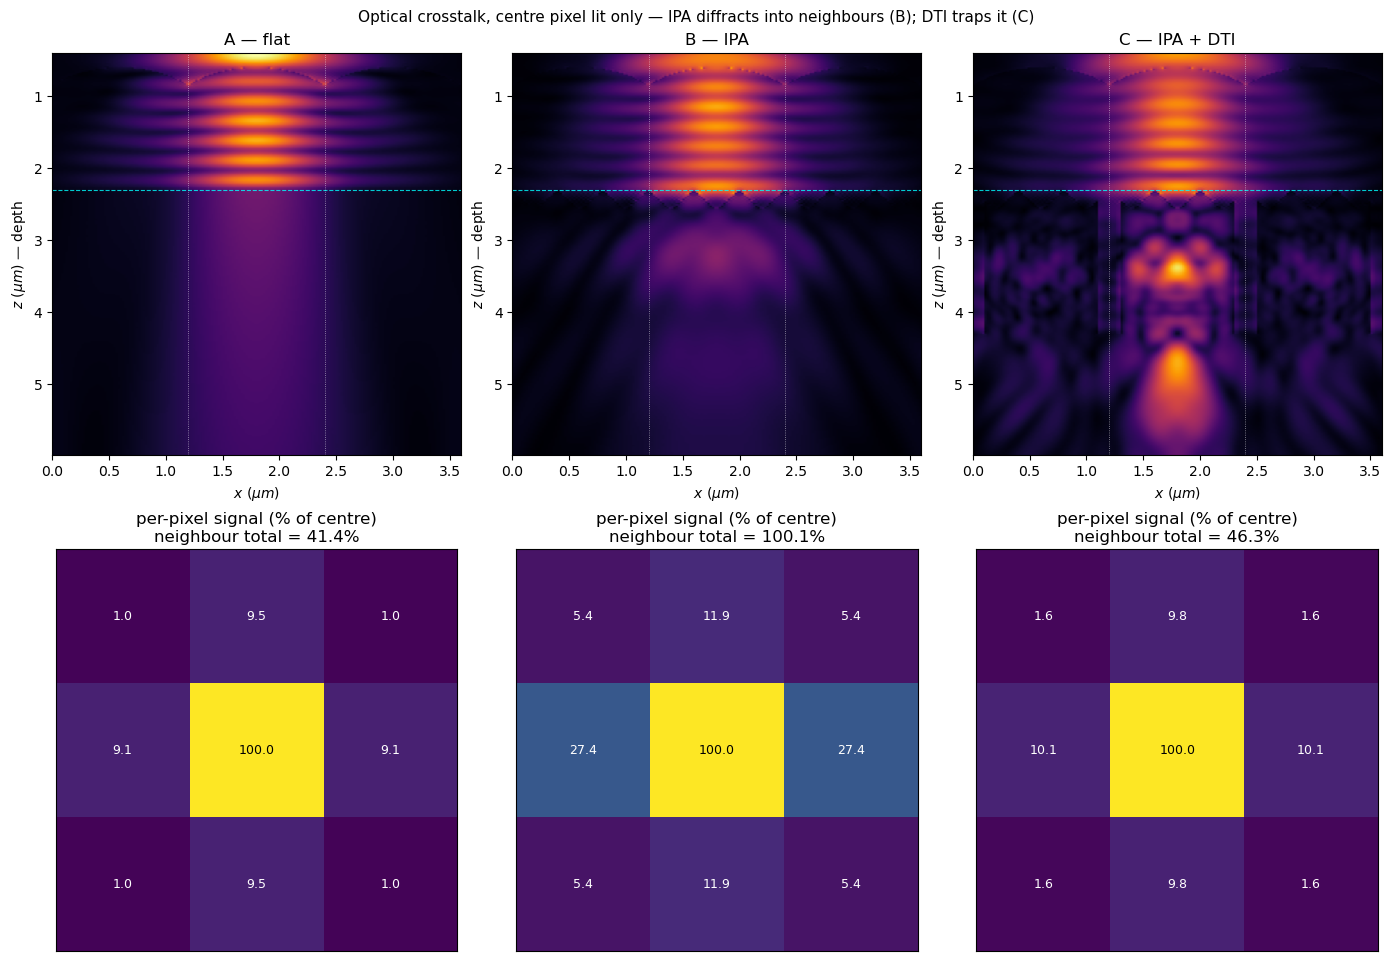

In [23]:
if RUN_CROSSTALK and signals:
    fig2, axes2 = plt.subplots(2, len(SAMPLES), figsize=(4.6 * len(SAMPLES), 9.5),
                               constrained_layout=True)
    vmax2 = max(m.max() for m in slices2.values())
    for j, sample in enumerate(SAMPLES):
        ax = axes2[0, j]
        extent = [0, n_pix * pix, z1, z0]
        ax.imshow(slices2[sample].T, cmap="inferno", extent=extent,
                  vmin=0, vmax=vmax2, aspect="auto")
        ax.axhline(z_si0, color="cyan", lw=0.8, ls="--", alpha=0.8)
        for k in range(1, n_pix):
            ax.axvline(k * pix, color="w", lw=0.6, ls=":", alpha=0.6)
        ax.set_title(titles[sample])
        ax.set_xlabel(r"$x~(\mu m)$")
        ax.set_ylabel(r"$z~(\mu m)$ — depth")

        ax = axes2[1, j]
        centre = signals[sample][cpx, cpx]
        s = signals[sample] / centre * 100  # % of centre
        im = ax.imshow(s, cmap="viridis", vmin=0, vmax=100)
        for (r, cix), v in np.ndenumerate(s):
            ax.text(cix, r, f"{v:.1f}", ha="center", va="center",
                    color="w" if v < 60 else "k", fontsize=9)
        ax.set_xticks([]), ax.set_yticks([])
        xt = (signals[sample].sum() - centre) / centre
        ax.set_title(f"per-pixel signal (% of centre)\nneighbour total = {xt*100:.1f}%")
    fig2.suptitle("Optical crosstalk, centre pixel lit only — IPA diffracts into "
                  "neighbours (B); DTI traps it (C)", fontsize=11)
    fig2.savefig(f"{OUTPUT_DIR}/mx_ipa_pixel_crosstalk.png", dpi=300,
                 bbox_inches="tight")

**Reading Figure 2.** Only the centre pixel is lit. Top row: |E| in an x-z cut through the centre row of pixels; the dotted lines are the pixel borders and the cyan line is the Si surface.
* **A, flat:** the light goes straight down as one column under the centre pixel.
* **B, pyramids:** below the surface the light fans out at steep angles and crosses the dotted borders into the neighbouring pixels.
* **C, pyramids + DTI:** the angled light is held between the trench walls, inside the centre pixel. Below the trench bottom (4.3 μm) it is no longer confined: the lobe at about 4.5–5.5 μm can spread sideways.

Bottom row: the signal each pixel absorbs, as % of the centre pixel. Sample A's neighbours (about 9 % each) are not crosstalk: they come from the tails of the Gaussian illumination. The meaningful number is the **excess over A**:

| array | A (baseline) | B | C | B − A | C − A |
|---|---|---|---|---|---|
| 3×3 | 41.3 % | 100.1 % | 46.2 % | **+59** | **+5** |
| 5×5 | 45.0 % | 130.3 % | 53.7 % | **+85** | **+9** |

Sample B leaks about as much light into its neighbours as it keeps at 3×3, and more at 5×5, where the second ring is included. Sample C's trenches cut the leak to a few percent. Its first ring sits slightly above flat (±x: 10.3 % vs 9.1 % at 5×5, 10.1 % vs 9.1 % at 3×3), from the light that passes under the 2 μm trenches. A trench through the full 3 μm of Si would be expected to close that path.

**Polarization:** the source is x-polarized, so B leaks hardest into ±x (about 27.5 % each, vs 11.9 % in ±y, at both array sizes). Unpolarized light would even out the split between x and y, but not the totals.

In [24]:
print(f"\nSaved output/{NAME}/mx_ipa_pixel_sensitivity.png"
      + (" and mx_ipa_pixel_crosstalk.png" if RUN_CROSSTALK else ""))
plt.show()


Saved output/mx_ipa_pixel/mx_ipa_pixel_sensitivity.png and mx_ipa_pixel_crosstalk.png
